# Credit Card Utilization

How much of their credit limit do people use, and what drives it? The data joins three tables: credit card applications, credit bureau records, and zip-code demographics.

**Utilization** = purchases ÷ credit limit. The model predicts its log-odds (`log_odds_util`); the plots below convert it back to a plain share between 0 and 1 so it is easy to read.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from src.utilization.config import Cfg
from src.utilization.data_ingestion import DataIngestion
from src.utilization.preprocessing import clean

sns.set_theme(style="whitegrid")

df = clean(DataIngestion().load_all())
utilization = 1 / (1 + np.exp(-df[Cfg.target]))
display(df.head())

,income,homeownership,credit_limit,fico,num_late,past_def,num_bankruptcy,avg_income,density,log_odds_util
0,47000.0,1,3100,427,3,1,1,48715.336345,119.707639,6.993451
1,71000.0,0,24300,743,0,0,0,85949.992971,252.706862,0.254796
2,38000.0,1,15200,640,0,0,0,59813.540000,19.556550,-0.218036
3,68000.0,1,25200,752,0,0,0,68412.209236,2031.962519,-0.605945
4,58000.0,0,35900,849,0,0,0,52102.276108,10.621670,-0.646780


The table above is the **cleaned** data: 500 applicants with the nine features and the target. `homeownership` is 1 for renters and 0 for owners.

## Summary statistics

Count, mean, spread and range for every column.

In [2]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
income,500.0,59546.00,24376.06,0.00,43000.00,59500.00,78000.00,123000.00
homeownership,500.0,0.70,0.46,0.00,0.00,1.00,1.00,1.00
credit_limit,500.0,20801.20,10374.40,300.00,12400.00,19400.00,29750.00,41300.00
fico,500.0,688.78,124.60,307.00,602.00,690.00,795.50,893.00
num_late,500.0,0.86,1.20,0.00,0.00,0.00,1.00,5.00
past_def,500.0,0.16,0.48,0.00,0.00,0.00,0.00,4.00
num_bankruptcy,500.0,0.17,0.50,0.00,0.00,0.00,0.00,3.00
avg_income,500.0,60280.67,14305.81,11674.63,51539.59,60348.68,69892.91,99560.27
density,500.0,338.55,545.32,0.01,31.32,143.87,389.65,3826.97
log_odds_util,500.0,1.50,3.66,-3.07,-0.92,0.42,2.79,20.27


## How much of their limit do people use?

The share of the credit limit each applicant used. The dashed line marks the median.

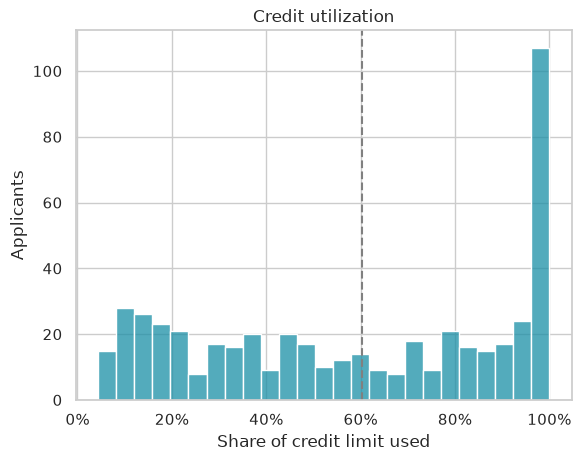

In [3]:
ax = sns.histplot(x=utilization, bins=25, color="#1A8FA6")
ax.axvline(utilization.median(), linestyle="--", color="gray")
ax.xaxis.set_major_formatter("{x:.0%}")
ax.set(title="Credit utilization", xlabel="Share of credit limit used", ylabel="Applicants")
plt.show()

## What moves with utilization?

The correlation of each feature with utilization: orange bars rise with it, blue bars fall with it.

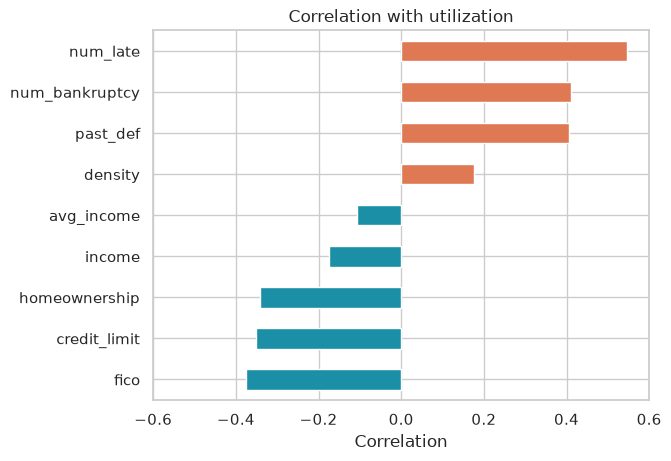

In [4]:
correlations = df[list(Cfg.features)].corrwith(utilization).sort_values()

ax = correlations.plot.barh(color=["#DF7953" if value > 0 else "#1A8FA6" for value in correlations])
ax.set(title="Correlation with utilization", xlabel="Correlation", xlim=(-0.6, 0.6))
plt.show()

## Late payments

Median utilization for applicants with each number of late payments.

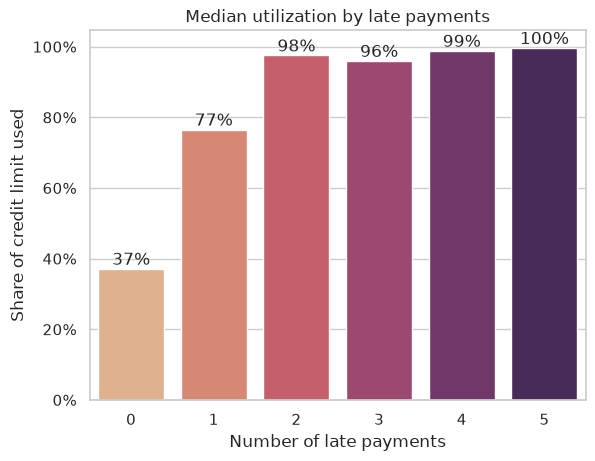

In [5]:
ax = sns.barplot(x=df["num_late"], y=utilization, hue=df["num_late"], palette="flare",
                 estimator="median", errorbar=None, legend=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:.0%}")
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set(title="Median utilization by late payments", xlabel="Number of late payments", ylabel="Share of credit limit used")
plt.show()

## Credit score

Applicants grouped into common FICO score bands. Each box covers the middle half of utilization in that band; the line inside is the median.

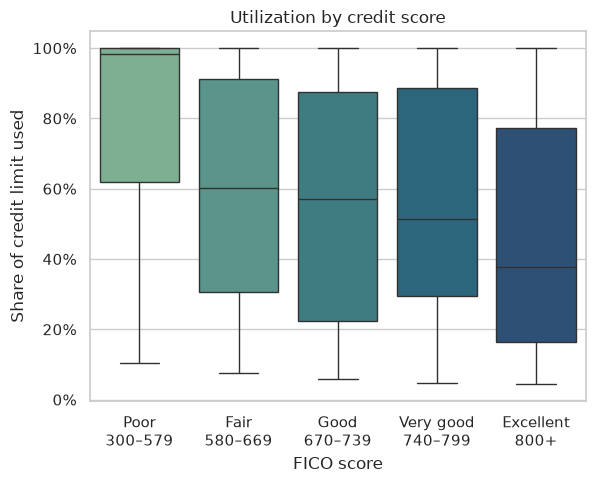

In [6]:
fico_band = pd.cut(df["fico"], bins=[300, 580, 670, 740, 800, 900],
                   labels=["Poor\n300–579", "Fair\n580–669", "Good\n670–739", "Very good\n740–799", "Excellent\n800+"])

ax = sns.boxplot(x=fico_band, y=utilization, hue=fico_band, palette="crest", dodge=False, legend=False)
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set(title="Utilization by credit score", xlabel="FICO score", ylabel="Share of credit limit used")
plt.show()

## How credit scores are spread

Every applicant's FICO score, coloured by the same bands as above, from poor (red) to excellent (green).

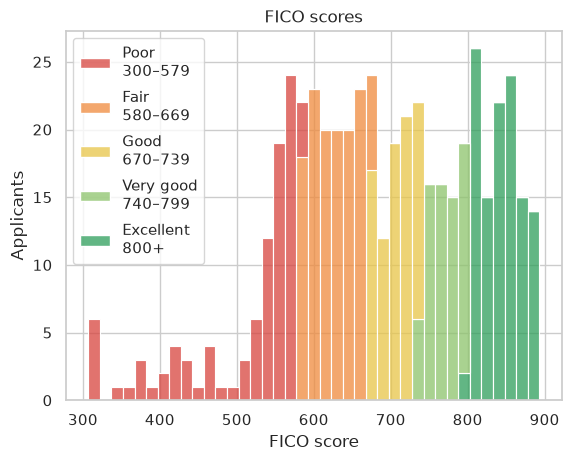

In [7]:
band_colors = ["#D7443E", "#EF8A3C", "#E8C547", "#8CC36B", "#2E9E5B"]

ax = sns.histplot(x=df["fico"], hue=fico_band, palette=band_colors, multiple="stack", binwidth=15)
ax.get_legend().set_title("")
ax.set(title="FICO scores", xlabel="FICO score", ylabel="Applicants")
plt.show()

## Credit score sets the credit limit

Each dot is one applicant: their FICO score against the credit limit they were given, coloured by score.

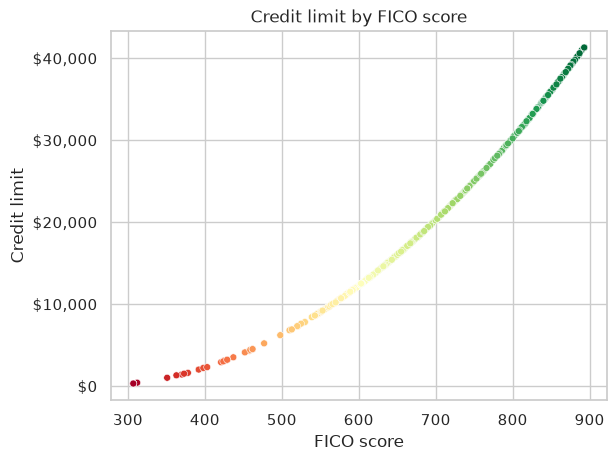

In [8]:
ax = sns.scatterplot(data=df, x="fico", y="credit_limit", hue="fico", palette="RdYlGn", s=25, legend=False)
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.set(title="Credit limit by FICO score", xlabel="FICO score", ylabel="Credit limit")
plt.show()

## Bankruptcies and credit score

The spread of FICO scores for applicants with 0, 1, 2 and 3 bankruptcies on record.

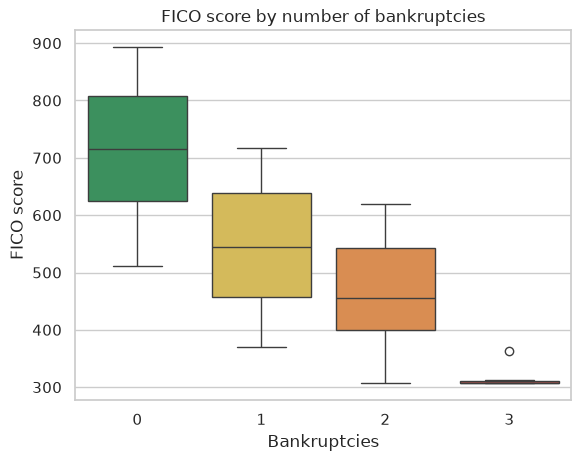

In [9]:
ax = sns.boxplot(data=df, x="num_bankruptcy", y="fico", hue="num_bankruptcy",
                 palette=["#2E9E5B", "#E8C547", "#EF8A3C", "#D7443E"], legend=False)
ax.set(title="FICO score by number of bankruptcies", xlabel="Bankruptcies", ylabel="FICO score")
plt.show()

## Late payments and credit score together

Each dot is one applicant: their FICO score against how much of their limit they use, coloured by how many late payments they have (light = none, dark = five).

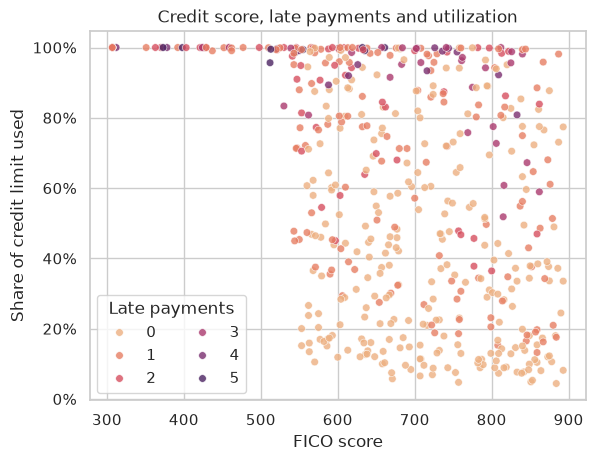

In [10]:
ax = sns.scatterplot(x=df["fico"], y=utilization, hue=df["num_late"], palette="flare", s=30, alpha=0.8)
ax.legend(title="Late payments", ncols=2)
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set(title="Credit score, late payments and utilization", xlabel="FICO score", ylabel="Share of credit limit used")
plt.show()